# 03 - 명시적 autograd 루프를 활용한 학습

이 노트북에서는 다음 요소들을 사용해 gradient 기반 최적화를 수행합니다.
- 모델 출력: `qc.expvals(thetas)`(`Circuit` 빌더 API)
- 표준 PyTorch loss / backward / optimizer step

학습 루프를 직접 작성하는 이유:
- `requires_grad` 여부, gradient 크기, 학습 안정성을 디버깅하기 쉽습니다.
- 내부에 숨겨진 학습 헬퍼(helper) 로직이 없어 동작이 투명합니다.

In [1]:
# 기본적인 학습 환경 구성: padopauli와 PyTorch만 불러옵니다.


import warnings
warnings.filterwarnings("ignore")

import torch

from padopauli import Circuit

In [2]:
n_qubits = 3

# 회전 게이트와 CNOT 사다리(0->1->2 반복)로 구성된 회로(Circuit 빌더 API 사용)
qc = Circuit(n_qubits=n_qubits)
idx = 0

# 레이어 0: 단일 큐비트 회전
for q in range(n_qubits):
    qc.rz(q, param_idx=idx); idx += 1
for q in range(n_qubits):
    qc.rx(q, param_idx=idx); idx += 1
# CNOT 사다리
qc.cnot(0, 1)
qc.cnot(1, 2)

# 레이어 1: 단일 큐비트 회전
for q in range(n_qubits):
    qc.rz(q, param_idx=idx); idx += 1
for q in range(n_qubits):
    qc.ry(q, param_idx=idx); idx += 1
# CNOT 사다리(역방향)
qc.cnot(1, 2)
qc.cnot(0, 1)

# 레이어 2: 마지막 회전
qc.rx(0, param_idx=idx); idx += 1
qc.ry(1, param_idx=idx); idx += 1
qc.rz(2, param_idx=idx); idx += 1

# 각 큐비트에 대한 단일 항 관측량 <Z_q>, (pauli, qubits) 튜플로 지정
obs = [("Z", [q]) for q in range(n_qubits)]

# 장치에 따른 설정: CUDA가 있으면 GPU 프리셋, 없으면 CPU 프리셋.
use_cuda = torch.cuda.is_available()
dev = "cuda" if use_cuda else "cpu"
nb_preset = "gpu" if use_cuda else "cpu"

torch.manual_seed(0)  # 재현성을 위한 학습 파라미터 초기화 시드 고정
thetas = torch.nn.Parameter(torch.randn(qc.n_params, dtype=torch.float32, device=dev))
program = qc.compile(observables=obs, preset=nb_preset)

propagate:   0%|          | 0/19 [00:00<?, ?it/s]

[PPS Info] Propagation complete. Terms generated: 6


zero-filter:   0%|          | 0/16 [00:00<?, ?it/s]

[PPS Info] Terms retained after pruning: 6 (100.000000% of peak)


## 목표 기댓값에 맞춰 파라미터 최적화

주요 텐서:
- `thetas`: 학습할 회로 파라미터
- `target`: 목표 기댓값 벡터
- `pred`: 컴파일된 surrogate가 계산한 모델 예측값
- `loss`: `pred`와 `target` 사이의 오차

컴파일 시점의 계수 절단(`build_min_abs`)을 사용하면 파라미터 경로가 제거되어 `build_thetas`에서 벗어난 지점에서 `pred`가 미분 불가능해질 수 있으므로, 학습 시에는 이 옵션을 사용하지 않습니다. `pred.requires_grad`는 반드시 `True`여야 하며, 그렇지 않다면 컴파일 과정에서 파라미터 경로가 잘려 나간 것입니다.

In [3]:
# 학습 파라미터
optimizer = torch.optim.Adam([thetas], lr=0.01)

target = torch.tensor([0.2, -0.1, 0.5], dtype=torch.float32, device=dev)

final loss: 2.1691070839349805e-14
final grad_norm: 1.48909848007861e-07
final thetas: tensor([-0.9247, -0.4253, -2.6438,  0.7116,  0.1892, -0.4444,  0.0242,  0.2329,
        -1.1532, -0.8918, -2.1144,  2.3678,  0.8185,  0.4202,  1.2866])
pred: tensor([ 0.2000, -0.1000,  0.5000], dtype=torch.float64)


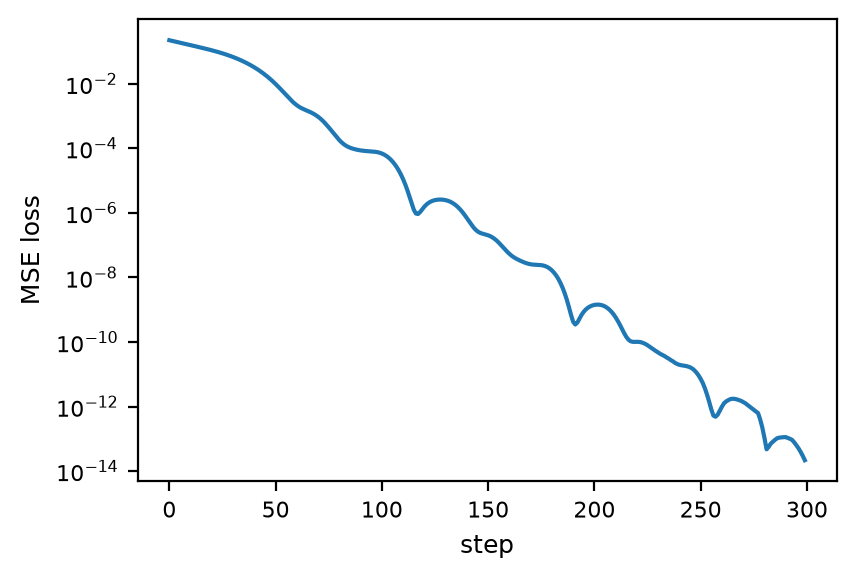

In [4]:
num_steps = 300
history = []

for step in range(num_steps):
    optimizer.zero_grad(set_to_none=True)

    pred = qc.expvals(thetas)
    loss_t = torch.mean((pred - target) ** 2)

    if not bool(pred.requires_grad):
        raise RuntimeError(
            "pred does not require gradients. If you compiled with build_min_abs, recompile without build_min_abs (or use a much smaller threshold)."
        )

    loss_t.backward()
    if thetas.grad is None:
        raise RuntimeError("No gradient on thetas after backward().")

    grad_norm = torch.linalg.vector_norm(thetas.grad.detach())
    optimizer.step()

    history.append(float(loss_t.detach().cpu().item()))

print("final loss:", history[-1])
print("final grad_norm:", float(grad_norm.detach().cpu().item()))
print("final thetas:", thetas.detach().cpu())
print("pred:", pred.detach().cpu())

from matplotlib import pyplot as plt
plt.rcParams.update({"font.size": 9, "axes.labelsize": 9, "axes.titlesize": 9,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
                     "figure.dpi": 200, "savefig.dpi": 200})
plt.figure(figsize=(4.51, 3.0))
plt.plot(history)
plt.yscale("log")
plt.xlabel("step")
plt.ylabel("MSE loss")
import os as _os; _os.makedirs("figures", exist_ok=True); plt.savefig("figures/fig_training_loss.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
# 컴파일 시점의 절단(build_min_abs) 값에 따른 프로그램 크기 및 실행 속도 비교
import time

def _step_nnz(prog):
    return prog.step_nnz   # 2.1.0: CompiledProgram.step_nnz

def _time_eval(prog, th, runs=50):
    _ = prog.expvals(th)
    t0 = time.perf_counter()
    for _ in range(runs):
        _ = prog.expvals(th)
    return (time.perf_counter() - t0) / runs

theta_build = thetas.detach().cpu().to(torch.float32)
theta_train = torch.nn.Parameter(theta_build.clone())
target_cpu = target.detach().cpu().to(torch.float32)

configs = [None, 1e-7, 1e-6, 1e-5]

rows = []
for b_abs in configs:
    t0 = time.perf_counter()
    prog = qc.compile(
        observables=obs,
        preset=nb_preset,
        build_thetas=theta_build,
        build_min_abs=b_abs,
    )
    compile_s = time.perf_counter() - t0

    nnz = _step_nnz(prog)
    eval_ms = 1e3 * _time_eval(prog, theta_build, runs=50)

    # 단일 스텝 gradient 확인
    th = torch.nn.Parameter(theta_train.detach().clone())
    pred = prog.expvals(th)
    loss = torch.mean((pred.cpu() - target_cpu) ** 2)
    loss.backward()
    grad_ok = th.grad is not None and bool(pred.requires_grad)

    rows.append((b_abs, compile_s, nnz, eval_ms, float(loss.detach()), grad_ok))

print('build_min_abs | compile(s) | total_nnz | eval(ms) | loss | grad_ok')
for r in rows:
    print(f'{str(r[0]):>12} | {r[1]:9.3f} | {r[2]:9d} | {r[3]:8.3f} | {r[4]:.3e} | {r[5]}')

propagate:   0%|          | 0/19 [00:00<?, ?it/s]

[PPS Info] Propagation complete. Terms generated: 6


zero-filter:   0%|          | 0/16 [00:00<?, ?it/s]

[PPS Info] Terms retained after pruning: 6 (100.000000% of peak)


propagate:   0%|          | 0/19 [00:00<?, ?it/s]

...

propagate:   0%|          | 0/19 [00:00<?, ?it/s]

[PPS Info] Propagation complete. Terms generated: 6


zero-filter:   0%|          | 0/16 [00:00<?, ?it/s]

[PPS Info] Terms retained after pruning: 6 (100.000000% of peak)


build_min_abs | compile(s) | total_nnz | eval(ms) | loss | grad_ok
        None |     0.036 |        69 |    0.932 | 1.469e-14 | True
       1e-07 |     0.087 |        69 |    0.942 | 1.469e-14 | True
       1e-06 |     0.038 |        69 |    0.965 | 1.469e-14 | True
       1e-05 |     0.037 |        69 |    0.935 | 1.469e-14 | True


## 비교 결과 해석

위 표는 `build_min_abs`(컴파일 시점에 θ 값을 기준으로 경로를 잘라내는 임계값) 설정에 따른 컴파일 시간, 비영(non-zero) 원소 수(`total_nnz`), 평가 소요 시간, 손실(loss) 값, 그리고 gradient 계산 가능 여부를 보여줍니다. 학습이 가능한 수준을 유지하면서 적절한 절단 임계값을 선택할 때 참고할 수 있습니다.

### 컴파일 시점 절단(`build_min_abs`)의 정확도·비용 트레이드오프

`build_min_abs`는 계수가 작은 경로를 컴파일 시점에 미리 제거합니다. 규모가 더 큰 회로(`max_weight=10` 제한이 실제로 작동하는 크기)에서 임계값을 높이면 정확한 상태벡터 결과와의 오차는 커지는 대신, 평가 시 처리해야 할 연산량이 줄어듭니다. 즉, 추론 단계에서 정확도와 계산 비용을 맞바꾸는 설정입니다.

propagate:   0%|          | 0/248 [00:00<?, ?it/s]

[PPS Info] Propagation complete. Terms generated: 92


zero-filter:   0%|          | 0/50 [00:00<?, ?it/s]

[PPS Info] Terms retained after pruning: 92 (100.000000% of peak)


propagate:   0%|          | 0/248 [00:00<?, ?it/s]

...

[PPS Info] Terms retained after pruning: 74 (100.000000% of peak)


propagate:   0%|          | 0/248 [00:00<?, ?it/s]

[PPS Info] Propagation complete. Terms generated: 56


zero-filter:   0%|          | 0/50 [00:00<?, ?it/s]

[PPS Info] Terms retained after pruning: 56 (100.000000% of peak)
build_min_abs=  None | |tensor-exact|=7.772e-15 | retained terms=2971
build_min_abs= 1e-06 | |tensor-exact|=1.333e-06 | retained terms=2538
build_min_abs= 1e-05 | |tensor-exact|=9.400e-06 | retained terms=2102
build_min_abs=0.0001 | |tensor-exact|=2.491e-04 | retained terms=1457


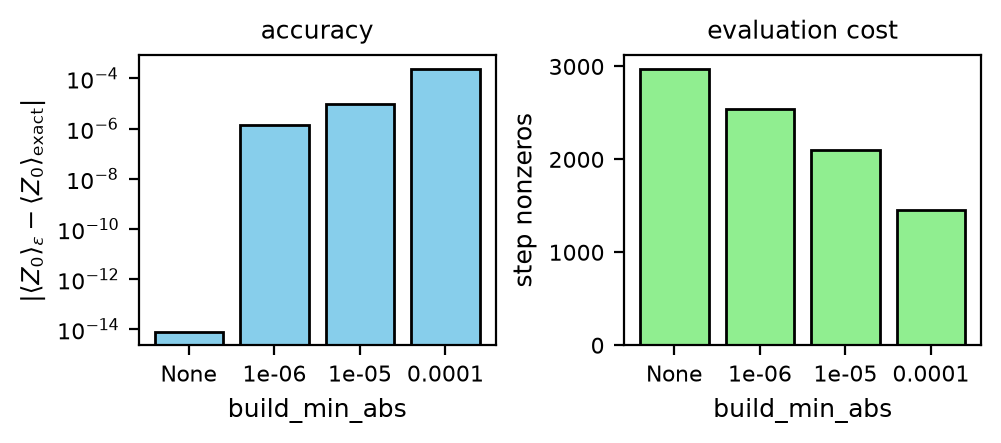

In [6]:
# 컴파일 시점의 계수 절단(build_min_abs, max_weight=10 고정):
# 정확한 상태벡터 대비 오차(왼쪽)와 평가 시 남는 연산량(오른쪽)
import time
import matplotlib.pyplot as plt

torch.manual_seed(0)
bma_nq = 16
bma_qc = Circuit(n_qubits=bma_nq)
_p = 0
for _pauli in ["Y", "Z", "X", "Y", "Z", "X", "Y", "Z"]:
    for _q in range(bma_nq):
        bma_qc.rot(_pauli, [_q], param_idx=_p); _p += 1
    for _q in range(bma_nq - 1):
        bma_qc.cnot(_q, _q + 1)
bma_theta = 1.1 * torch.randn(_p, dtype=torch.float64)
bma_obs = ("Z", [0])  # (pauli, qubits) 튜플로 지정한 단일 항 관측량

# Circuit 내장 PennyLane 상태벡터 시뮬레이션으로 정확한 <Z_0> 계산(expvals_reference는
# build_min_abs 절단 설정과 무관하게 동작하므로 한 번만 컴파일해 호출하면 됨).
bma_qc.compile(observables=[bma_obs], preset=nb_preset, max_weight=10)
bma_exact = float(bma_qc.expvals_reference(bma_theta)[0])

def _retained_terms(prog):
    return prog.step_nnz   # 2.1.0: CompiledProgram.step_nnz

bma_values = [None, 1e-6, 1e-5, 1e-4]
bma_dev, bma_terms = [], []
for _bma in bma_values:
    _prog = bma_qc.compile(
        observables=[bma_obs], preset=nb_preset, max_weight=10,
        build_thetas=bma_theta, build_min_abs=_bma)
    bma_dev.append(abs(float(_prog.expvals(bma_theta)[0]) - bma_exact))
    bma_terms.append(_retained_terms(_prog))

for _b, _d, _t in zip(bma_values, bma_dev, bma_terms):
    print(f"build_min_abs={str(_b):>6} | |tensor-exact|={_d:.3e} | retained terms={_t}")

_labels = [str(b) for b in bma_values]
fig, ax = plt.subplots(1, 2, figsize=(4.89, 2.1), constrained_layout=True)
ax[0].bar(_labels, bma_dev, color="skyblue", edgecolor="black")
ax[0].set_yscale("log"); ax[0].set_title("accuracy")
ax[0].set_ylabel(r"$|\langle Z_0\rangle_\epsilon - \langle Z_0\rangle_{\rm exact}|$"); ax[0].set_xlabel("build_min_abs")
ax[1].bar(_labels, bma_terms, color="lightgreen", edgecolor="black")
ax[1].set_title("evaluation cost")
ax[1].set_ylabel("step nonzeros"); ax[1].set_xlabel("build_min_abs")
import os as _os; _os.makedirs("figures", exist_ok=True); plt.savefig("figures/fig_build_min_abs.png", dpi=150, bbox_inches="tight")
plt.show()